# Krylov-Komplexität

Das Notebook berechnet mit dem Lanczos-Algorithmus die Krylov-Kette des Operators $X$ in der Mitte der Mixed-Field-Ising-Kette, mit vollen Matrizen bis 11 Qubits und für die integrable Kette mit freien Majorana-Fermionen bis 101 Qubits: die Lanczos-Koeffizienten (linear wachsend gegen beschränkt), die vollständige Kette eines kleinen Systems bis zu ihrem Ende, die Krylov-Komplexität $K(t)$ und die Autokorrelation, die in der Kette steckt.

Wie wächst ein lokaler Operator in den Raum aller Operatoren hinein, und warum wachsen die Lanczos-Koeffizienten einer chaotischen Kette linear, die einer integrablen aber nicht?

#### **Hintergrund**

Unter der Zeitentwicklung wird ein einfacher Operator, etwa $X$ auf einem Qubit, zu einer Überlagerung immer längerer und verwickelterer Operatoren. Wie schnell das geht, misst man üblicherweise mit OTOCs im Ortsraum ([Quantum Chaos and Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/chaos_scrambling.ipynb)). Die Krylov-Methode fragt stattdessen, wie weit der Operator in einer bestimmten, vom Hamiltonoperator selbst erzeugten Folge von Operatoren vorankommt. Diese Folge entsteht durch wiederholtes Bilden des Kommutators mit $H$ und anschließendes Orthogonalisieren, den **Lanczos-Algorithmus**, der seit 1950 zur Diagonalisierung großer Matrizen dient und in der Theorie der Relaxation (Mori, Zwanzig, Viswanath und Müller) die Dynamik einer Observablen in eine Kette mit Sprungamplituden $b_n$ übersetzt.

Parker, Cao, Avdoshkin, Scaffidi und Altman haben 2019 vorgeschlagen, dass diese $b_n$ in chaotischen Systemen so schnell wie möglich wachsen, nämlich linear in $n$, und dass daraus ein exponentielles Wachstum der **Krylov-Komplexität** folgt, mit einer Rate, die auch den Lyapunov-Exponenten begrenzt. Seitdem ist Krylov-Komplexität ein Werkzeug, um Chaos ohne Ortsstruktur zu messen, etwa im SYK-Modell, in Zufallsschaltkreisen und in Modellen der Holographie, wo sie mit geometrischen Größen hinter dem Horizont eines Schwarzen Lochs verglichen wird. In endlichen Systemen hat die Kette ein Ende, und der Weg dorthin („die Reise zum Rand des Krylov-Raums“) zeigt den Unterschied zwischen chaotischen und integrablen Systemen besonders deutlich.

Das Notebook nimmt dieselbe Ising-Kette wie die anderen Notebooks der Serie ($J = h_x = 1$; chaotisch bei $h_z = 0.5$, integrabel bei $h_z = 0$) und den Operator $X$ auf dem mittleren Qubit.

Landkarte:

- **Die Koeffizienten**
  - Lanczos-Koeffizienten (Exp. 1): chaotisch wachsen sie linear, $b_n \approx 0.40\,n + 3.2$; integrabel bleiben sie bei 4, der Hälfte der größten Frequenz, und die Kette endet nach 111 Gliedern.
  - Die ganze Kette (Exp. 2): Bei 6 Qubits hat die chaotische Kette 4036 Glieder, fast so viele wie es Operatoren gibt (4096); die integrable nur 61. $K(t)$ sättigt chaotisch erst nach einigen hundert Zeiteinheiten bei etwa 1600, integrabel schon nach $t \approx 5$ bei etwa 26.
- **Die Dynamik**
  - Krylov-Komplexität (Exp. 3): chaotisch exponentiell, mit einer Rate, die von oben gegen $2\alpha = 0.80$ geht; integrabel linear mit 7.4 pro Zeiteinheit.
  - Autokorrelation (Exp. 4): Die erste Komponente der Krylov-Welle ist genau die Autokorrelation $\langle X(t)X\rangle$ aus der exakten Diagonalisierung.

Verwandte Notebooks: [Quantum Chaos and Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/chaos_scrambling.ipynb) (OTOCs, freie Fermionen, Theorie des Operatorwachstums), [Eigenzustands-Thermalisierung](https://github.com/deltorobarba/science/blob/main/quantum/chaos_eth.ipynb) (dieselbe Observable in der Eigenbasis, Frequenzgrenze 8 der freien Fermionen), [Spektralstatistik und Quantenchaos](https://github.com/deltorobarba/science/blob/main/quantum/chaos_spectra.ipynb), [Zufallsmatrizen](https://github.com/deltorobarba/science/blob/main/maths/randommatrices.ipynb) (Tridiagonalmodelle von Zufallsmatrizen).

#### **Theorie**

##### *1. Operatoren als Vektoren*

Die Operatoren auf $N$ Qubits bilden einen Vektorraum der Dimension $4^N$ (Basis: die Pauli-Strings). Das **Skalarprodukt bei unendlicher Temperatur** ist
$$(A\vert B) = \frac{1}{2^N}\mathrm{Tr}(A^\dagger B), \qquad \Vert A\Vert^2 = (A\vert A) ,$$
sodass jeder Pauli-String die Norm 1 hat. Die Heisenberg-Zeitentwicklung $O(t) = e^{iHt}Oe^{-iHt}$ ist in diesem Raum eine lineare Abbildung, erzeugt vom **Liouville-Operator** $\mathcal L = [H, \cdot\,]$:
$$O(t) = e^{i\mathcal Lt}O = O + it\,[H, O] - \frac{t^2}{2}[H, [H, O]] + \dots$$
$\mathcal L$ ist bezüglich des Skalarprodukts hermitesch; seine Eigenwerte sind die Frequenzen $\omega = E_m - E_n$.

##### *2. Krylov-Raum und Lanczos-Algorithmus*

Der **Krylov-Raum** von $O$ ist $\mathrm{span}\lbrace O, \mathcal LO, \mathcal L^2O, \dots\rbrace$, alle Operatoren, die die Zeitentwicklung erreichen kann. Der Lanczos-Algorithmus baut darin eine Orthonormalbasis $O_0, O_1, \dots$:
$$O_0 = \frac{O}{\Vert O\Vert}, \qquad A_n = \mathcal LO_{n-1} - b_{n-1}O_{n-2}, \qquad b_n = \Vert A_n\Vert, \qquad O_n = \frac{A_n}{b_n} .$$
Die **Lanczos-Koeffizienten** $b_n > 0$ sind die Normen der neuen Anteile. Bei unendlicher Temperatur und hermiteschem $O$ verschwinden alle Diagonalterme $(O_n\vert\mathcal L\vert O_n)$; bei reellem $H$ und reellem $O$ sind alle $O_n$ reelle Matrizen. Endet die Folge ($b_n = 0$), ist der Krylov-Raum erschöpft; seine Dimension ist höchstens die Zahl der verschiedenen Frequenzen, also höchstens $D^2 - D + 1$ für einen Hilbertraum der Dimension $D$.

In der Rechnung gehen kleine Rundungsfehler die Orthogonalität verloren. Für lange Ketten orthogonalisiert man deshalb jeden neuen Vektor erneut gegen alle früheren (**Reorthogonalisierung**). In der chaotischen Kette reichen für 40 Schritte die einfachen Formeln (Experiment 1 prüft das); in der integrablen ist der Krylov-Raum so klein, dass Rundungsfehler aus ihm herausführen und schnell wachsen. Deshalb rechnet das Notebook die integrable Kette mit freien Fermionen (Abschnitt 5).

##### *3. Die Krylov-Kette*

In der Lanczos-Basis wird die Zeitentwicklung zu einem Teilchen, das auf einer halbunendlichen Kette hüpft:
$$O(t) = \sum_n i^n\varphi_n(t)\,O_n, \qquad \frac{d\varphi_n}{dt} = b_n\varphi_{n-1} - b_{n+1}\varphi_{n+1}, \qquad \varphi_n(0) = \delta_{n0} .$$
Die Sprungamplituden sind die $b_n$, und $\sum_n\varphi_n^2 = 1$. Die erste Komponente ist die **Autokorrelation**,
$$\varphi_0(t) = \frac{(O(t)\vert O)}{(O\vert O)} ,$$
und die **Krylov-Komplexität** ist die mittlere Position des Teilchens,
$$K(t) = \sum_n n\,\varphi_n(t)^2 .$$
Die Folge $b_n$ enthält damit die ganze Dynamik von $O$. Sie folgt eindeutig aus den Momenten $\mu_{2k} = (O\vert\mathcal L^{2k}\vert O)$ der Spektralfunktion von $O$, also aus der Autokorrelation; umgekehrt bestimmen die $b_n$ diese vollständig.

##### *4. Universelles Operatorwachstum*

Mit lokalen Wechselwirkungen kann $b_n$ höchstens linear in $n$ wachsen (in einer Dimension asymptotisch höchstens wie $n/\ln n$). Die **Hypothese des universellen Operatorwachstums** (Parker et al. 2019) besagt: In chaotischen Systemen wachsen die $b_n$ so schnell wie möglich,
$$b_n \approx \alpha n + \gamma ,$$
in integrablen langsamer, etwa wie $n^\delta$ mit $\delta < 1$, und bei freien Teilchen bleiben sie beschränkt. Daraus folgt das Wachstum von $K$: Für $b_n = \alpha\sqrt{n(n - 1 + \eta)}$ ist exakt $K(t) = \eta\sinh^2(\alpha t)$, also wächst $K$ für große $t$ wie $e^{2\alpha t}$, und die lokale Rate $d\ln K/dt = 2\alpha\coth(\alpha t)$ nähert sich $2\alpha$ von oben. Konstante $b_n = b$ geben ein Teilchen, das mit Geschwindigkeit bis $2b$ über die Kette läuft, und $K$ wächst linear.

Parker et al. zeigen, dass $2\alpha$ den Lyapunov-Exponenten begrenzt, $\lambda_L \le 2\alpha$, und dass $K(t)$ eine ganze Klasse anderer Komplexitätsmaße nach oben begrenzt, darunter die Operatorgröße. Bei endlicher Temperatur (mit dem thermischen Skalarprodukt) argumentieren sie $\alpha \le \pi k_BT/\hbar$, was die Schranke von Maldacena, Shenker und Stanford wiedergibt. Hier, bei unendlicher Temperatur, ist $\alpha$ ein effektiver Wert für die ersten etwa 25 Schritte.

##### *5. Freie Fermionen: eine beschränkte Kette*

In der integrablen Kette ($h_z = 0$) ist $X_c = i\gamma_{2c}\gamma_{2c+1}$ quadratisch in den Majorana-Fermionen (Jordan-Wigner, siehe [Quantum Chaos and Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/chaos_scrambling.ipynb), Theorie Abschnitt 2), ebenso $H = \frac i4\sum A_{ab}\gamma_a\gamma_b$. Der Kommutator zweier quadratischer Formen ist wieder quadratisch und entspricht dem Kommutator der antisymmetrischen $2N\times2N$-Matrizen. Der Krylov-Raum bleibt deshalb im Raum der quadratischen Formen, der nur $N(2N - 1)$ Dimensionen hat statt $4^N$, und der Lanczos-Algorithmus läuft mit $2N\times2N$-Matrizen, für 101 Qubits mühelos.

Die Frequenzen dieses Raums sind $\pm\varepsilon_k \pm \varepsilon_q$ mit Quasiteilchenenergien $\varepsilon_k \le 2(J + h_x) = 4$, also liegen sie in $[-8, 8]$. Ist die Spektralfunktion auf $[-\Lambda, \Lambda]$ beschränkt, gehen die $b_n$ gegen $\Lambda/2$, hier gegen 4. Dieselbe Grenze 8 zeigte sich in [Eigenzustands-Thermalisierung](https://github.com/deltorobarba/science/blob/main/quantum/chaos_eth.ipynb), Experiment 3, als Abbruch der Nichtdiagonalelemente.

##### *6. Endliche Systeme: die Reise zum Rand des Krylov-Raums*

In einem endlichen System ist die Krylov-Kette endlich. Bei einem chaotischen System hat sie fast die Länge $D^2$, die Zahl aller Operatoren; die $b_n$ steigen zuerst linear, erreichen ein Maximum und fallen dann über Tausende Schritte langsam auf null (Rabinovici, Sánchez-Garrido, Shir und Sonner 2021). $K(t)$ wächst erst exponentiell, dann linear und sättigt nach einer Zeit, die exponentiell mit $N$ wächst, bei einem großen Bruchteil der Kettenlänge. Die integrable Kette ist dagegen von vornherein kurz: Der Operator erkundet nur einen winzigen Teil des Operatorraums.

#### **Code**

Die Werkzeuge für alle Experimente:
- `ising_sparse` und `site_x`: die Kette und $X$ auf einem Qubit als Matrizen; `liouville(H)` ist der Liouville-Operator $\mathcal L = [H, \cdot\,]$;
- `majorana_A` und `majorana_x`: dieselbe integrable Kette und dasselbe $X$ als antisymmetrische $2N\times2N$-Matrizen der freien Fermionen (Theorie, Abschnitt 5); auch hier ist $\mathcal L$ der Kommutator;
- `lanczos` berechnet die Koeffizienten $b_n$ (Abschnitt 2), wahlweise mit Reorthogonalisierung;
- `krylov_wave` löst die Hüpfgleichung auf der Krylov-Kette (Abschnitt 3) über die Eigenzerlegung der Tridiagonalmatrix, `krylov_complexity` gibt $K(t)$;
- `autocorrelation` berechnet $\langle X(t)X\rangle$ direkt aus der exakten Diagonalisierung, zum Vergleich.

In [1]:
# Alles hier (numpy, scipy, matplotlib) ist in Colab vorinstalliert
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.linalg import eigh_tridiagonal

def ising_sparse(n, h_x, h_z, J=1.0):
    """Mixed-Field-Ising-Kette H = J Σ Z_i Z_i+1 + Σ h_x,i X_i + Σ h_z,i Z_i mit offenen Enden, als dünne Matrix.
    h_x und h_z sind Zahlen (homogen) oder Arrays der Länge n (ein Feld pro Platz). Qubit 0 ist das höchste Bit."""
    h_x, h_z = np.broadcast_to(h_x, n).astype(float), np.broadcast_to(h_z, n).astype(float)
    s = np.arange(2 ** n)
    z = 1 - 2 * ((s[:, None] >> (n - 1 - np.arange(n))) & 1)          # z[s, i] = Eigenwert von Z_i im Zustand s
    rows, cols, vals = [s], [s], [J * (z[:, :-1] * z[:, 1:]).sum(1) + z @ h_z]
    for i in range(n):                                                 # X_i kippt das Bit von Qubit i
        rows.append(s); cols.append(s ^ (1 << (n - 1 - i))); vals.append(np.full(2 ** n, h_x[i]))
    return sparse.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(2 ** n, 2 ** n))

def site_x(n, j):
    """X auf Qubit j als dichte Matrix."""
    s = np.arange(2 ** n)
    return sparse.csr_matrix((np.ones(2 ** n), (s, s ^ (1 << (n - 1 - j)))), shape=(2 ** n, 2 ** n)).toarray()

def majorana_A(n, h_x, J=1.0):
    """Integrable Kette (h_z = 0) als freie Majorana-Fermionen: H = (i/4) Σ A_ab γ_a γ_b (Theorie, Abschnitt 5)."""
    A = np.zeros((2 * n, 2 * n))
    A[np.arange(0, 2 * n, 2), np.arange(1, 2 * n, 2)] = 2 * h_x
    A[np.arange(1, 2 * n - 2, 2), np.arange(2, 2 * n - 1, 2)] = 2 * J
    return A - A.T

def majorana_x(n, j):
    """X_j = i γ_2j γ_2j+1 als antisymmetrische 2n×2n-Matrix (bis auf einen Faktor, der die b_n nicht ändert)."""
    M = np.zeros((2 * n, 2 * n))
    M[2 * j, 2 * j + 1] = 1
    return M - M.T

def lanczos(L, O, steps, reorth=True, tol=1e-8):
    """Lanczos-Koeffizienten b_1, b_2, ... des Operators O unter dem Liouville-Operator L (Theorie, Abschnitt 2).
    Operatoren sind reelle Matrizen, das Skalarprodukt ist Tr(AᵀB) bis auf einen festen Faktor.
    reorth=True: jeder neue Vektor wird gegen alle früheren orthogonalisiert (nötig für lange Ketten)."""
    v = O.ravel() / np.linalg.norm(O)
    basis = np.zeros((steps + 1, v.size)) if reorth else None
    if reorth:
        basis[0] = v
    prev, b = np.zeros_like(v), []
    for n in range(steps):
        w = L(v.reshape(O.shape)).ravel() - (b[-1] * prev if b else 0)
        if reorth:
            for _ in range(2):
                w -= basis[:n + 1].T @ (basis[:n + 1] @ w)
        bn = np.linalg.norm(w)
        if bn < tol:                                                   # die Krylov-Kette ist zu Ende
            break
        b.append(bn)
        prev, v = v, w / bn
        if reorth:
            basis[n + 1] = v
    return np.array(b)

def krylov_wave(b, times):
    """Wahrscheinlichkeiten |φ_n(t)|² auf der Krylov-Kette und φ_0(t) (Theorie, Abschnitt 3).
    Mit ψ_n = i^n φ_n gilt i dψ/dt = T ψ mit der reellen Tridiagonalmatrix T (Nebendiagonale b)."""
    w, V = eigh_tridiagonal(np.zeros(len(b) + 1), b)
    amp = np.exp(-1j * np.outer(times, w)) * V[0]                    # Koeffizienten von e_0 in der Eigenbasis
    psi = amp @ V.T                                                   # ψ(t) für alle Zeiten
    return np.abs(psi) ** 2, psi[:, 0].real

def krylov_complexity(b, times):
    """K(t) = Σ n |φ_n(t)|²."""
    p, _ = krylov_wave(b, times)
    return p @ np.arange(p.shape[1])

def autocorrelation(H, O, times):
    """C(t) = Tr(O(t) O) / Tr(O²) direkt aus der exakten Diagonalisierung (zum Vergleich mit φ_0)."""
    E, U = np.linalg.eigh(H)
    W = np.abs(U.T @ O @ U) ** 2
    W /= W.sum()
    omega = np.subtract.outer(E, E)
    return np.array([np.sum(W * np.cos(omega * t)) for t in times])

H_X, H_Z = 1.0, 0.5                                                    # wie in den anderen Notebooks der Serie (J = 1)
liouville = lambda H: (lambda X: H @ X - X @ H)                        # L = [H, ·]
print("Werkzeuge bereit: Ising-Kette, freie Fermionen, Lanczos, Krylov-Kette")

Werkzeuge bereit: Ising-Kette, freie Fermionen, Lanczos, Krylov-Kette


#### **Experimente**

##### *1. Die Lanczos-Koeffizienten: linear oder beschränkt?*

Wie wachsen die Lanczos-Koeffizienten von $X$ in der Kettenmitte, und unterscheidet sich die chaotische von der integrablen Kette schon in den ersten Schritten? Vorher vorhersagen: Welcher Wert sollte für die integrable Kette herauskommen, wenn die größte Frequenz 8 ist?

Für die chaotische Kette läuft der Lanczos-Algorithmus 40 Schritte mit vollen $2^N\times2^N$-Matrizen, für $N = 9$ und $N = 11$ (etwa 10 s); eine Kontrolle mit 8 Qubits vergleicht die Rechnung ohne und mit Reorthogonalisierung. Für die integrable Kette läuft er mit freien Fermionen für $N = 11$ bis zum Ende der Kette und für $N = 101$ über 200 Schritte. Eine Gerade durch $b_5$ bis $b_{25}$ der chaotischen Kette mit $N = 11$ gibt die Wachstumsrate $\alpha$ (Theorie, Abschnitt 4).

**Hintergrund & Fachbegriffe:**
- **Lanczos-Koeffizient $b_n$:** die Sprungamplitude zwischen dem $(n-1)$-ten und dem $n$-ten Glied der Krylov-Kette, also wie stark der Kommutator mit $H$ Neues erzeugt.
- **Endliche Größe:** Der $n$-te Kommutator reicht höchstens $n$ Plätze weit; solange er die Enden der Kette nicht erreicht, hängt $b_n$ nicht von $N$ ab.
- **Reorthogonalisierung:** jeden neuen Basisvektor noch einmal gegen alle früheren orthogonalisieren, um Rundungsfehler zu entfernen.

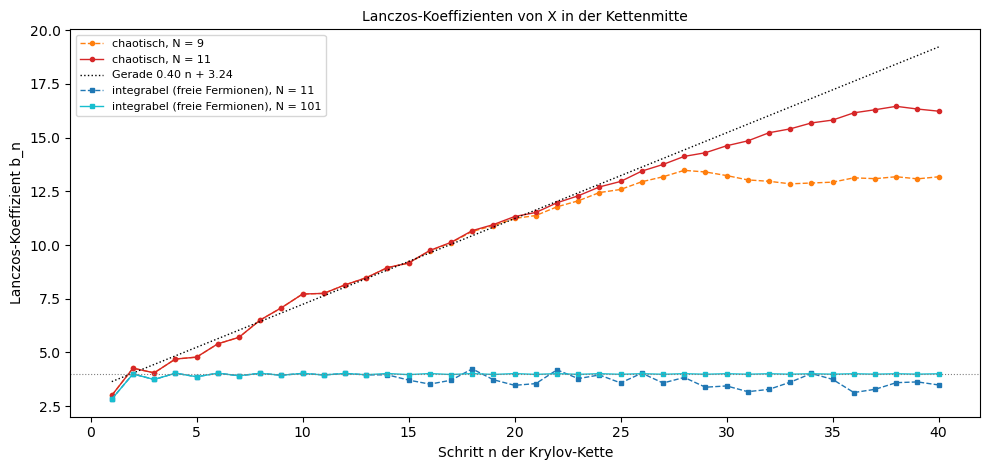

(9 s)  Kontrolle N = 8: größte Abweichung ohne/mit Reorthogonalisierung 3.7e-12
chaotisch N = 11, b_1 ... b_40: 3.00 4.27 4.05 4.69 4.78 5.40 5.71 6.51 7.08 7.72 7.75 8.14 8.48 8.95 9.17 9.75 10.13 10.67 10.95 11.33 11.52 11.97 12.29 12.71 12.96 13.44 13.75 14.13 14.30 14.62 14.85 15.23 15.41 15.69 15.82 16.16 16.30 16.46 16.33 16.23
  Anstieg aus n = 5 ... 25: b_n ≈ 0.400 n + 3.24;  N = 9 weicht ab n = 19 um mehr als 0.05 ab
integrabel N =  11: b_1 ... b_8 = 2.83 4.00 3.74 4.04 3.87 4.03 3.92 4.03,  größtes b_n = 4.236,  Krylov-Kette endet nach 111 Gliedern
integrabel N = 101: b_1 ... b_8 = 2.83 4.00 3.74 4.04 3.87 4.03 3.92 4.03,  größtes b_n = 4.062,  nach 200 Schritten abgebrochen


In [2]:
t0 = time.time()
b_chaos = {}
for n in [9, 11]:                                                      # chaotisch: volle Matrizen, 40 Schritte
    b_chaos[n] = lanczos(liouville(ising_sparse(n, H_X, H_Z).toarray()), site_x(n, (n - 1) // 2), 40, reorth=False)
H8, O8 = ising_sparse(8, H_X, H_Z).toarray(), site_x(8, 3)             # Kontrolle: ohne gegen mit Reorthogonalisierung
check = np.abs(lanczos(liouville(H8), O8, 40, reorth=False) - lanczos(liouville(H8), O8, 40)).max()
b_free = {n: lanczos(liouville(majorana_A(n, H_X)), majorana_x(n, (n - 1) // 2), steps) for n, steps in [(11, 400), (101, 200)]}
n_fit = np.arange(5, 26)
alpha, offset = np.polyfit(n_fit, b_chaos[11][n_fit - 1], 1)

fig, ax = plt.subplots(figsize=(10, 4.8))
for n, c, ls in [(9, "tab:orange", "--"), (11, "tab:red", "-")]:
    ax.plot(np.arange(1, len(b_chaos[n]) + 1), b_chaos[n], "o" + ls, c=c, ms=3, lw=1, label=f"chaotisch, N = {n}")
ax.plot(np.arange(1, 41), alpha * np.arange(1, 41) + offset, "k:", lw=1, label=f"Gerade {alpha:.2f} n + {offset:.2f}")
for n, c, ls in [(11, "tab:blue", "--"), (101, "tab:cyan", "-")]:
    ax.plot(np.arange(1, 41), b_free[n][:40], "s" + ls, c=c, ms=3, lw=1, label=f"integrabel (freie Fermionen), N = {n}")
ax.axhline(4, color="grey", ls=":", lw=0.8)
ax.set_xlabel("Schritt n der Krylov-Kette")
ax.set_ylabel("Lanczos-Koeffizient b_n")
ax.set_title("Lanczos-Koeffizienten von X in der Kettenmitte", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"({time.time() - t0:.0f} s)  Kontrolle N = 8: größte Abweichung ohne/mit Reorthogonalisierung {check:.1e}")
print("chaotisch N = 11, b_1 ... b_40: " + " ".join(f"{x:.2f}" for x in b_chaos[11]))
print(f"  Anstieg aus n = 5 ... 25: b_n ≈ {alpha:.3f} n + {offset:.2f};  N = 9 weicht ab n = {np.argmax(np.abs(b_chaos[9] - b_chaos[11]) > 0.05) + 1} um mehr als 0.05 ab")
for n in b_free:
    print(f"integrabel N = {n:3d}: b_1 ... b_8 = " + " ".join(f"{x:.2f}" for x in b_free[n][:8]) +
          f",  größtes b_n = {b_free[n].max():.3f},  " + (f"Krylov-Kette endet nach {len(b_free[n]) + 1} Gliedern" if len(b_free[n]) < 200 else "nach 200 Schritten abgebrochen"))

* Das **Bild** zeigt $b_n$ gegen $n$. Die chaotische Kette (rot, $N = 11$) wächst linear und folgt der gepunkteten Geraden $0.40\,n + 3.24$ bis etwa $n = 30$; danach biegt sie ab, weil der Operator die Enden der Kette erreicht. Mit $N = 9$ (orange) geschieht das früher, ab $n = 19$, und die Koeffizienten bleiben bei etwa 13 stehen. Die integrable Kette (blau) bleibt von Anfang an bei 4 (grau gepunktet): Die Koeffizienten wachsen nicht.
* Mit 101 Qubits (türkis) schwanken die integrablen $b_n$ immer weniger um 4, die Hälfte der größten Frequenz 8 der freien Fermionen (Theorie, Abschnitt 5). Mit 11 Qubits (blau gestrichelt) weichen sie ab $n \approx 14$ nach unten ab, weil der Krylov-Raum dort schon fast erschöpft ist.
* Die **Ausgabe** gibt $b_n \approx 0.400\,n + 3.24$ für die chaotische Kette und bestätigt, dass ohne Reorthogonalisierung nichts verloren geht (Abweichung $4\cdot10^{-12}$). Die integrable Kette mit 11 Qubits endet nach 111 Gliedern, ihr größtes $b_n$ ist 4.24; mit 101 Qubits ist es 4.06.

##### *2. Die ganze Krylov-Kette einer kleinen Kette*

Wie sieht die Krylov-Kette eines endlichen Systems bis zu ihrem Ende aus, und wie weit kommt der Operator in ihr? Vorher vorhersagen: Wie lang ist die Kette bei 6 Qubits höchstens, und wie lang ist sie für die integrable Kette?

Für $N = 6$ hat der Operatorraum $4^6 = 4096$ Dimensionen. Der Lanczos-Algorithmus mit Reorthogonalisierung läuft für die chaotische Kette bis zum Ende (etwa 20 s), für die integrable mit freien Fermionen. Der Operator ist $X$ auf Qubit 2. **Links:** alle $b_n$, mit logarithmischer $n$-Achse. **Rechts:** $K(t)$ von $t = 0.01$ bis $10^4$, mit der halben Kettenlänge als gepunkteter Linie.

**Hintergrund & Fachbegriffe:**
- **Krylov-Dimension:** die Zahl der Glieder der Kette, also die Dimension des Teilraums, den der Operator unter der Zeitentwicklung überhaupt erreichen kann.
- **Sättigung:** In einer endlichen Kette verteilt sich das Teilchen nach langer Zeit über alle Glieder, und $K$ schwankt um einen festen Wert.
- **Raum der quadratischen Formen:** die Operatoren, die sich als $\sum M_{ab}\gamma_a\gamma_b$ schreiben lassen; für 6 Qubits $6\cdot11 = 66$ Dimensionen.

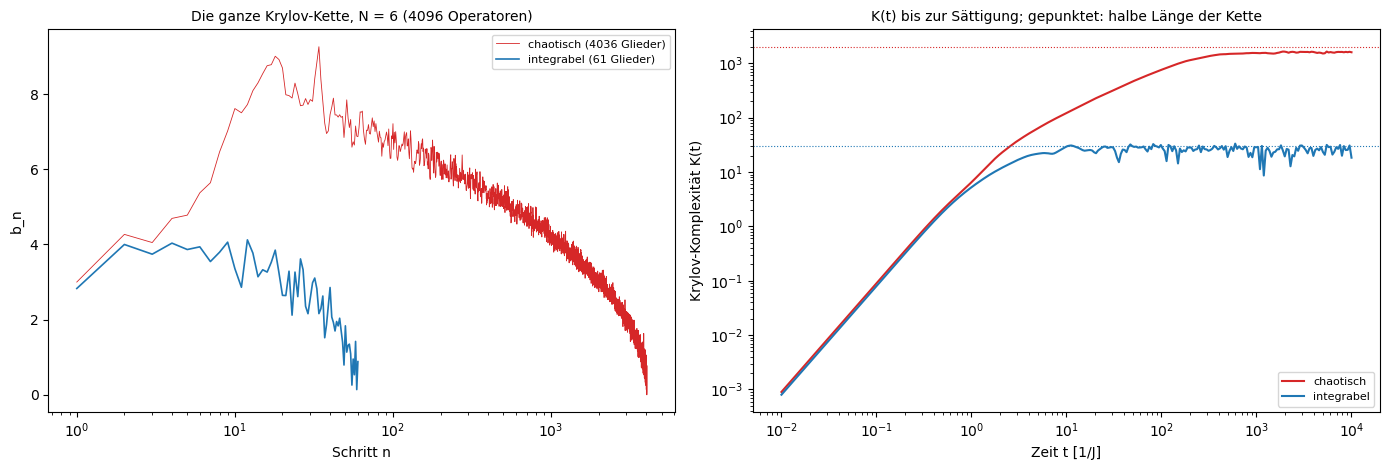

N = 6 (20 s): Operatorraum 4^6 = 4096
  chaotisch:  Krylov-Kette mit 4036 Gliedern, größtes b_n = 9.26 bei n = 34, b_n bei n = 1000, 2000, 3000: 4.08, 2.94, 2.06
  integrabel: Krylov-Kette mit 61 Gliedern (Raum der Fermion-Bilinearformen: 66)
  chaotisch : K bei t = 10, 100, 1000: 119.3, 753.2, 1546.7;  Mittel t > 3000: 1596.6 (halbe Kettenlänge 2018.0); K erreicht ein Viertel der Länge bei t ≈ 156
  integrabel: K bei t = 10, 100, 1000: 28.8, 31.4, 28.6;  Mittel t > 3000: 26.0 (halbe Kettenlänge 30.5); K erreicht ein Viertel der Länge bei t ≈ 3


In [3]:
N2 = 6
t0 = time.time()
b_full = lanczos(liouville(ising_sparse(N2, H_X, H_Z).toarray()), site_x(N2, 2), 4 ** N2)
b_full_free = lanczos(liouville(majorana_A(N2, H_X)), majorana_x(N2, 2), 4 * N2 * N2)
long_times = np.geomspace(0.01, 1e4, 300)
K_full = krylov_complexity(b_full, long_times)
K_full_free = krylov_complexity(b_full_free, long_times)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(np.arange(1, len(b_full) + 1), b_full, c="tab:red", lw=0.6, label=f"chaotisch ({len(b_full) + 1} Glieder)")
axes[0].plot(np.arange(1, len(b_full_free) + 1), b_full_free, c="tab:blue", lw=1.2, label=f"integrabel ({len(b_full_free) + 1} Glieder)")
axes[0].set_xscale("log")
axes[0].set_xlabel("Schritt n")
axes[0].set_ylabel("b_n")
axes[0].set_title(f"Die ganze Krylov-Kette, N = {N2} ({4 ** N2} Operatoren)", fontsize=10)
axes[0].legend(fontsize=8)
for K, b, c, label in [(K_full, b_full, "tab:red", "chaotisch"), (K_full_free, b_full_free, "tab:blue", "integrabel")]:
    axes[1].loglog(long_times, K, c=c, label=label)
    axes[1].axhline((len(b) + 1) / 2, color=c, ls=":", lw=0.8)
axes[1].set_xlabel("Zeit t [1/J]")
axes[1].set_ylabel("Krylov-Komplexität K(t)")
axes[1].set_title("K(t) bis zur Sättigung; gepunktet: halbe Länge der Kette", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"N = {N2} ({time.time() - t0:.0f} s): Operatorraum 4^{N2} = {4 ** N2}")
print(f"  chaotisch:  Krylov-Kette mit {len(b_full) + 1} Gliedern, größtes b_n = {b_full.max():.2f} bei n = {b_full.argmax() + 1}, "
      f"b_n bei n = 1000, 2000, 3000: {b_full[999]:.2f}, {b_full[1999]:.2f}, {b_full[2999]:.2f}")
print(f"  integrabel: Krylov-Kette mit {len(b_full_free) + 1} Gliedern (Raum der Fermion-Bilinearformen: {N2 * (2 * N2 - 1)})")
late = long_times > 3000
for label, K, b in [("chaotisch", K_full, b_full), ("integrabel", K_full_free, b_full_free)]:
    t_half = long_times[np.argmax(K > 0.25 * (len(b) + 1))]
    print(f"  {label:10s}: K bei t = 10, 100, 1000: {K[np.argmin(abs(long_times - 10))]:.1f}, {K[np.argmin(abs(long_times - 100))]:.1f}, "
          f"{K[np.argmin(abs(long_times - 1000))]:.1f};  Mittel t > 3000: {K[late].mean():.1f} (halbe Kettenlänge {(len(b) + 1) / 2:.1f}); "
          f"K erreicht ein Viertel der Länge bei t ≈ {t_half:.0f}")

* Das **linke Bild** zeigt die ganze Kette. Die chaotischen $b_n$ (rot) steigen bis $n = 34$ auf 9.3, dann fallen sie über Tausende Schritte langsam ab, auf 4.1 bei $n = 1000$, 2.9 bei 2000 und 2.1 bei 3000, und gehen am Ende, nach 4035 Schritten, gegen null: die Reise zum Rand des Krylov-Raums. Die integrable Kette (blau) endet nach 61 Gliedern, bevor sie richtig begonnen hat.
* Das **rechte Bild** zeigt $K(t)$ doppelt logarithmisch. Anfangs wachsen beide gleich, wie $t^2$ ($K \approx b_1^2t^2$). Die integrable Kette sättigt ab $t \approx 5$ bei etwa 26, knapp unter der halben Kettenlänge 30.5. Die chaotische wächst weiter, über $119$ bei $t = 10$ und $753$ bei $t = 100$, und sättigt erst nach einigen hundert Zeiteinheiten bei etwa 1600, etwas unter der halben Länge 2018.
* Die **Ausgabe** gibt eine chaotische Kette mit 4036 Gliedern, fast so viele wie es Operatoren gibt (4096): Der Operator erreicht fast den ganzen Operatorraum. Die integrable hat 61 von 66 möglichen quadratischen Formen. Ein Viertel ihrer Länge erreicht $K$ bei der integrablen Kette bei $t \approx 3$, bei der chaotischen erst bei $t \approx 156$.

##### *3. Krylov-Komplexität: exponentiell gegen linear*

Wächst die Krylov-Komplexität der chaotischen Kette exponentiell, und mit welcher Rate? Vorher vorhersagen: Welche Rate folgt aus $b_n \approx 0.40\,n$, und wie wächst $K$ bei konstanten $b_n = 4$?

$K(t)$ wird aus den 40 Koeffizienten der chaotischen Kette mit 11 Qubits berechnet, solange das Abschneiden der Kette nichts ändert (verglichen mit nur 30 Koeffizienten), und aus den 200 Koeffizienten der freien Fermionen mit 101 Qubits. Um das Verhalten einer unendlich langen Kette zu sehen, setzt eine zweite chaotische Kurve die Koeffizienten ab $n = 41$ mit der Geraden aus Experiment 1 fort, bis $n = 4000$; diese Kurve ist eine Extrapolation, keine Rechnung. **Links** lineare, **rechts** logarithmische $K$-Achse.

**Hintergrund & Fachbegriffe:**
- **Krylov-Komplexität $K(t)$:** die mittlere Position des Operators auf der Krylov-Kette, ein Maß dafür, wie verwickelt er geworden ist.
- **Lokale Wachstumsrate:** $d\ln K/dt$; bei exponentiellem Wachstum ist sie konstant.
- **Abschneiden:** Eine Kette mit nur $M$ Gliedern ist richtig, solange das Teilchen ihr Ende nicht erreicht hat; danach wird es zurückgeworfen.

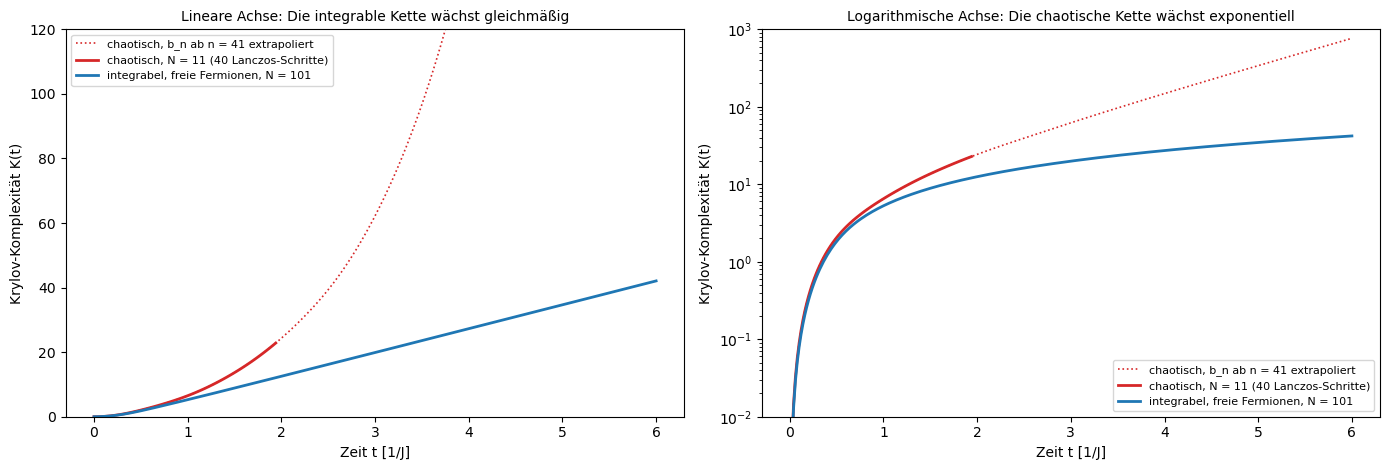

chaotisch: die abgeschnittene Kette ist bis t = 1.94 genau (K = 22.8)
  lokale Wachstumsrate d ln K / dt bei t = 1, 2, 4, 6: 1.71, 1.04, 0.84, 0.81;  Anpassung 4 < t < 6: 0.82,  2α = 0.80
integrabel: K wächst für t > 2 linear mit 7.39 pro Zeiteinheit;  K(t = 2, 4, 6) = 12.5, 27.3, 42.1


In [4]:
times = np.linspace(0, 6, 301)
K_chaos = {m: krylov_complexity(b_chaos[11][:m], times) for m in (30, 40)}   # abgeschnittene Kette: 30 und 40 Glieder
b_ext = np.r_[b_chaos[11], alpha * np.arange(41, 4001) + offset]               # Extrapolation: b_n = α n + c ab n = 41
K_ext = krylov_complexity(b_ext, times)
K_free = krylov_complexity(b_free[101], times)
ok = np.abs(K_chaos[40] - K_chaos[30]) < 0.01 * K_chaos[40] + 1e-3          # wo das Abschneiden noch nichts ändert
t_ok = times[ok][-1] if ok.all() else times[np.argmin(ok)]
late_ext = (times > 4) & (times < 6)
rate_ext = np.polyfit(times[late_ext], np.log(K_ext[late_ext]), 1)[0]
local_rate = np.gradient(np.log(K_ext + 1e-300), times)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, scale in [(axes[0], "linear"), (axes[1], "log")]:
    ax.plot(times, K_ext, ":", c="tab:red", lw=1.2, label="chaotisch, b_n ab n = 41 extrapoliert")
    ax.plot(times[times <= t_ok], K_chaos[40][times <= t_ok], c="tab:red", lw=2, label="chaotisch, N = 11 (40 Lanczos-Schritte)")
    ax.plot(times, K_free, c="tab:blue", lw=2, label="integrabel, freie Fermionen, N = 101")
    ax.set_yscale(scale)
    ax.set_xlabel("Zeit t [1/J]")
    ax.set_ylabel("Krylov-Komplexität K(t)")
axes[0].set_ylim(0, 120)
axes[1].set_ylim(1e-2, 1e3)
axes[0].set_title("Lineare Achse: Die integrable Kette wächst gleichmäßig", fontsize=10)
axes[1].set_title("Logarithmische Achse: Die chaotische Kette wächst exponentiell", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

slope_free = np.polyfit(times[times > 2], K_free[times > 2], 1)[0]
print(f"chaotisch: die abgeschnittene Kette ist bis t = {t_ok:.2f} genau (K = {K_chaos[40][times <= t_ok][-1]:.1f})")
print(f"  lokale Wachstumsrate d ln K / dt bei t = 1, 2, 4, 6: " + ", ".join(f"{local_rate[np.argmin(abs(times - t))]:.2f}" for t in (1, 2, 4, 6))
      + f";  Anpassung 4 < t < 6: {rate_ext:.2f},  2α = {2 * alpha:.2f}")
print(f"integrabel: K wächst für t > 2 linear mit {slope_free:.2f} pro Zeiteinheit;  K(t = 2, 4, 6) = "
      + ", ".join(f"{K_free[np.argmin(abs(times - t))]:.1f}" for t in (2, 4, 6)))

* Das **linke Bild** zeigt den Unterschied auf linearer Achse: Die integrable Kette (blau) wächst ab $t \approx 1$ als Gerade, wie ein Teilchen, das mit fester Geschwindigkeit über die Kette läuft. Die chaotische (rot, durchgezogen bis $t = 1.94$, wo das Abschneiden spürbar wird) biegt nach oben ab, und die Extrapolation (gepunktet) steigt immer steiler.
* Das **rechte Bild** zeigt dasselbe auf logarithmischer Achse: Die extrapolierte chaotische Kurve wird für $t > 3$ eine Gerade, also exponentielles Wachstum; die integrable wird immer flacher, wie es für lineares Wachstum auf dieser Achse sein muss.
* Die **Ausgabe** gibt die lokale Rate der chaotischen Kurve: 1.71 bei $t = 1$, 1.04 bei $t = 2$, 0.84 bei $t = 4$, 0.81 bei $t = 6$; eine Anpassung für $4 < t < 6$ gibt 0.82, nahe an $2\alpha = 0.80$. Die Rate nähert sich $2\alpha$ von oben, wie $2\alpha\coth(\alpha t)$ aus Theorie, Abschnitt 4. Die integrable Kette wächst mit 7.39 pro Zeiteinheit, knapp unter der größten Geschwindigkeit $2b = 8$ auf einer Kette mit $b_n = 4$.

##### *4. Die Autokorrelation steckt in der Kette*

Steckt in der Krylov-Kette wirklich die Dynamik des Operators? Vorher vorhersagen: Wie lange stimmt die Autokorrelation aus 40 Koeffizienten mit der exakten überein, und was passiert danach?

Für $N = 11$ wird die Autokorrelation $C(t) = \langle X_c(t)X_c\rangle/\langle X_c^2\rangle$ einmal direkt aus der exakten Diagonalisierung berechnet und einmal als $\varphi_0(t)$ aus der Krylov-Kette (Theorie, Abschnitt 3): chaotisch aus den 40 Koeffizienten von Experiment 1, integrabel aus der vollständigen Kette mit 111 Gliedern.

**Hintergrund & Fachbegriffe:**
- **Autokorrelation:** wie ähnlich der Operator zur Zeit $t$ seinem Anfangswert noch ist; ihr Abfall beschreibt, wie schnell $X_c$ relaxiert.
- **Spektralfunktion:** die Fourier-Transformierte der Autokorrelation; ihre Momente legen die $b_n$ fest.
- **Erhaltungsgröße:** $H$ selbst ändert sich nicht; der Teil von $X_c$, der in Richtung $H$ zeigt, zerfällt deshalb nie.

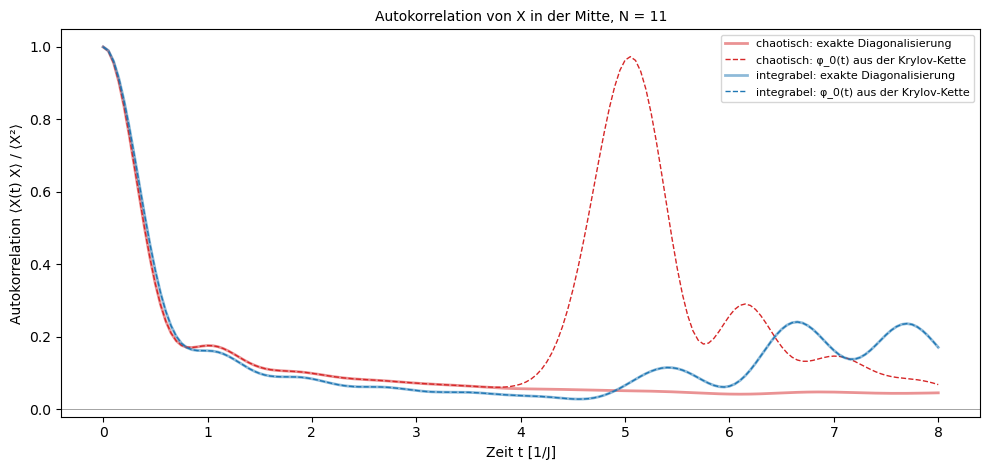

(7 s)
chaotisch : Krylov und exakte Rechnung stimmen bis t = 3.75 auf 1e-3 überein;  C(t = 1, 2) = +0.176, +0.100;  Betrag im Mittel für t > 3: 0.051
integrabel: Krylov und exakte Rechnung stimmen bis t = 8.00 auf 1e-3 überein;  C(t = 1, 2) = +0.162, +0.085;  Betrag im Mittel für t > 3: 0.108


In [5]:
times4 = np.linspace(0, 8, 161)
N4 = 11
t0 = time.time()
C_ed = {"chaotisch": autocorrelation(ising_sparse(N4, H_X, H_Z).toarray(), site_x(N4, 5), times4),
        "integrabel": autocorrelation(ising_sparse(N4, H_X, 0.0).toarray(), site_x(N4, 5), times4)}
phi0 = {"chaotisch": krylov_wave(b_chaos[11], times4)[1], "integrabel": krylov_wave(b_free[11], times4)[1]}

fig, ax = plt.subplots(figsize=(10, 4.8))
for label, c in [("chaotisch", "tab:red"), ("integrabel", "tab:blue")]:
    ax.plot(times4, C_ed[label], c=c, lw=2, alpha=0.5, label=f"{label}: exakte Diagonalisierung")
    ax.plot(times4, phi0[label], "--", c=c, lw=1, label=f"{label}: φ_0(t) aus der Krylov-Kette")
ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("Zeit t [1/J]")
ax.set_ylabel("Autokorrelation ⟨X(t) X⟩ / ⟨X²⟩")
ax.set_title(f"Autokorrelation von X in der Mitte, N = {N4}", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"({time.time() - t0:.0f} s)")
for label in C_ed:
    dev = np.abs(C_ed[label] - phi0[label])
    agree = times4[np.argmax(dev > 1e-3)] if (dev > 1e-3).any() else times4[-1]
    late = times4 > 3
    print(f"{label:10s}: Krylov und exakte Rechnung stimmen bis t = {agree:.2f} auf 1e-3 überein;  "
          f"C(t = 1, 2) = {C_ed[label][20]:+.3f}, {C_ed[label][40]:+.3f};  Betrag im Mittel für t > 3: {np.abs(C_ed[label][late]).mean():.3f}")

* Das **Bild** zeigt beide Autokorrelationen. Bis $t \approx 1$ fallen sie fast gleich von 1 auf etwa 0.17, danach langsam weiter. Die gestrichelten Krylov-Kurven liegen auf den breiten Kurven der exakten Rechnung: integrabel über die ganze Zeit, weil die Kette vollständig ist, chaotisch bis $t \approx 3.75$. Danach erzeugt die abgeschnittene chaotische Kette einen falschen Buckel bei $t \approx 5$: Die Welle ist am Ende der 40 Glieder angekommen und wird zurückgeworfen.
* Die exakte chaotische Autokorrelation bleibt ab $t \approx 3$ bei etwa 0.05 stehen. Das liegt daran, dass $X_c$ ein Stück der erhaltenen Energie ist ($H$ enthält $h_x X_c$): Der Anteil von $X_c$ in Richtung $H$, $h_x^2/(\mathrm{Tr}H^2/2^N) = 1/23.75 = 0.042$, zerfällt nie. Für eine längere Kette wird dieser Anteil wie $1/N$ kleiner. Die integrable Autokorrelation steigt ab $t \approx 4.5$ wieder an, weil die Quasiteilchen an den Enden der Kette reflektiert werden (wie der Lichtkegel in [Quantum Chaos and Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/chaos_scrambling.ipynb), Experiment 1).
* Die **Ausgabe** gibt die Übereinstimmung auf $10^{-3}$: chaotisch bis $t = 3.75$, integrabel bis zum Ende bei $t = 8$. $C(1)$ und $C(2)$ sind 0.176 und 0.100 (chaotisch), 0.162 und 0.085 (integrabel); der mittlere Betrag für $t > 3$ ist 0.051 bzw. 0.108.

#### **Ergebnis**

Beim Lauf vom 2026-10-24 (Operator $X$ in der Kettenmitte, $J = h_x = 1$):

- **Lanczos-Koeffizienten (Experiment 1):** chaotisch ($h_z = 0.5$, $N = 11$) wachsen sie linear, $b_n \approx 0.400\,n + 3.24$ für $n = 5$ bis 25; mit $N = 9$ biegen sie ab $n = 19$ ab. Integrabel bleiben sie bei 4, der Hälfte der größten Frequenz 8 der freien Fermionen (größter Wert 4.24 bei 11, 4.06 bei 101 Qubits), und die Kette endet bei 11 Qubits nach 111 Gliedern.
- **Die ganze Kette (Experiment 2):** Bei 6 Qubits hat die chaotische Kette 4036 Glieder, fast alle 4096 Operatoren; die $b_n$ steigen bis 9.3 ($n = 34$) und fallen dann über Tausende Schritte auf null. Die integrable Kette hat 61 Glieder. $K(t)$ sättigt integrabel ab $t \approx 5$ bei 26, chaotisch erst nach einigen hundert Zeiteinheiten bei etwa 1600.
- **Krylov-Komplexität (Experiment 3):** chaotisch exponentiell, die lokale Rate fällt von 1.71 ($t = 1$) auf 0.81 ($t = 6$, mit extrapolierten $b_n$) und nähert sich $2\alpha = 0.80$ von oben; integrabel linear mit 7.39 pro Zeiteinheit, knapp unter $2b = 8$.
- **Autokorrelation (Experiment 4):** $\varphi_0(t)$ aus der Krylov-Kette stimmt mit der exakten Autokorrelation auf $10^{-3}$ überein, chaotisch bis $t = 3.75$ (danach wirft die abgeschnittene Kette die Welle zurück), integrabel über die ganze Zeit. Die chaotische Autokorrelation bleibt bei 0.05 stehen, wovon 0.042 aus der Energieerhaltung kommen.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Ein String-Operator:** In Experiment 1 statt $X$ den Operator $Z$ auf dem mittleren Qubit nehmen (`np.diag(1.0 - 2 * ((np.arange(2 ** n) >> (n - 1 - c)) & 1))` mit `c = (n - 1) // 2`), für beide Ketten mit vollen Matrizen und `n = 9`. *(Vorhersage: chaotisch wieder linear wachsende $b_n$. Integrabel ist $Z_c$ in den Fermionen kein quadratischer Ausdruck, sondern ein langer String; die $b_n$ wachsen dann genau wie $2\sqrt n$, also 2.00, 2.83, 3.46, 4.00, …, und $K$ wächst wie $t^2$, nicht linear.)*
2. **Schwaches Chaos:** `H_Z = 0.1` in Experiment 1. *(Vorhersage: Die $b_n$ bleiben bis $n \approx 7$ bei 4 wie in der integrablen Kette und wachsen erst dann linear, mit kleinerer Steigung, etwa 0.34.)*
3. **Am Rand statt in der Mitte:** $X$ auf Qubit 0. *(Vorhersage: $b_1 = \sqrt5 \approx 2.24$ statt 3, weil am Rand nur ein Nachbar ist, und eine etwas kleinere Steigung, etwa 0.34.)*
4. **Eine noch kleinere Kette:** `N2 = 5` in Experiment 2. *(Vorhersage: chaotisch 995 Glieder von $4^5 = 1024$ Operatoren, integrabel 21; die Sättigung von $K$ kommt bei beiden früher.)*
5. **Die logarithmische Korrektur:** In Experiment 3 die Extrapolation mit $b_n = \alpha n/\ln n$ statt mit einer Geraden fortsetzen, mit $\alpha$ so gewählt, dass $b_{40}$ stimmt. *(Vorhersage: Die lokale Rate fällt immer weiter, langsam, statt bei einem festen Wert stehen zu bleiben: In einer Dimension wächst $K$ streng genommen etwas langsamer als exponentiell.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Was ist der Liouville-Operator, und warum kann man die Zeitentwicklung eines Operators als Vektor betrachten?</summary>

$\mathcal L = [H, \cdot\,]$ wirkt linear auf dem Raum der Operatoren, der mit $(A\vert B) = \mathrm{Tr}(A^\dagger B)/2^N$ ein Vektorraum mit Skalarprodukt ist, für $N$ Qubits mit Dimension $4^N$. Die Heisenberg-Zeitentwicklung ist $O(t) = e^{i\mathcal Lt}O$, wie eine Schrödinger-Gleichung im Operatorraum.
</details>

<details><summary>2. Was macht der Lanczos-Algorithmus, und was sind die Koeffizienten b_n?</summary>

Er orthogonalisiert die Folge $O, \mathcal LO, \mathcal L^2O, \dots$ zu einer Basis $O_0, O_1, \dots$, in der $\mathcal L$ tridiagonal ist. Die $b_n$ sind die Nebendiagonale: wie stark der Kommutator mit $H$ aus $O_{n-1}$ etwas Neues erzeugt.
</details>

<details><summary>3. Was ist die Krylov-Kette, und was misst die Krylov-Komplexität?</summary>

In der Lanczos-Basis wird die Zeitentwicklung zu einem Teilchen, das mit den Amplituden $b_n$ auf einer halbunendlichen Kette hüpft. $K(t) = \sum n\varphi_n^2$ ist seine mittlere Position: wie weit der Operator in die Folge immer verwickelterer Operatoren vorgedrungen ist.
</details>

<details><summary>4. Was besagt die Hypothese des universellen Operatorwachstums?</summary>

In chaotischen Systemen wachsen die $b_n$ so schnell, wie lokale Wechselwirkungen erlauben: linear, $b_n \approx \alpha n$ (in einer Dimension mit logarithmischer Korrektur). Dann wächst $K$ exponentiell mit Rate $2\alpha$, und $2\alpha$ begrenzt den Lyapunov-Exponenten.
</details>

<details><summary>5. Warum bleiben die b_n der integrablen Kette bei 4?</summary>

$X_c$ und $H$ sind quadratisch in den Majorana-Fermionen, deshalb bleibt der ganze Krylov-Raum bei quadratischen Formen. Deren Frequenzen $\pm\varepsilon_k\pm\varepsilon_q$ liegen in $[-8, 8]$, und für eine auf $[-\Lambda, \Lambda]$ beschränkte Spektralfunktion gehen die $b_n$ gegen $\Lambda/2 = 4$.
</details>

<details><summary>6. Wie wächst K(t) bei linear wachsenden, bei konstanten und bei wie die Wurzel wachsenden b_n?</summary>

Linear: exponentiell, $K \sim e^{2\alpha t}$. Konstant: linear, das Teilchen läuft mit fester Geschwindigkeit bis $2b$. Wie $\sqrt n$: quadratisch, $K \propto t^2$. Allgemein gibt $b_n \propto n^\delta$ mit $\delta < 1$ ein Potenzgesetz $K \propto t^{1/(1-\delta)}$.
</details>

<details><summary>7. Warum nähert sich die gemessene Wachstumsrate 2α von oben?</summary>

Weil die Kette mit einem großen Anfangswert beginnt ($b_n \approx 0.4\,n + 3.2$). Für das exakt lösbare Modell $b_n = \alpha\sqrt{n(n - 1 + \eta)}$ ist $K = \eta\sinh^2(\alpha t)$ mit der Rate $2\alpha\coth(\alpha t)$, die für große $t$ von oben gegen $2\alpha$ geht. Gemessen: 1.71, 1.04, 0.84, 0.81 gegen 0.80.
</details>

<details><summary>8. Wie lang ist die Krylov-Kette in einem endlichen System, und wie sieht ihr Ende aus?</summary>

Höchstens so lang wie die Zahl der verschiedenen Frequenzen, $D^2 - D + 1$. Chaotisch fast so lang: 4036 von 4096 bei 6 Qubits; die $b_n$ steigen, erreichen ein Maximum und fallen über Tausende Schritte auf null. Integrabel viel kürzer: 61 Glieder.
</details>

<details><summary>9. Warum ist die einfache Lanczos-Rechnung für die integrable Kette numerisch instabil?</summary>

Ihr Krylov-Raum ist winzig im Vergleich zum Operatorraum. Rundungsfehler erzeugen Anteile außerhalb dieses Raums, die der Liouville-Operator in jedem Schritt verstärkt. Die Rechnung mit freien Fermionen bleibt dagegen im richtigen Raum und ist exakt.
</details>

<details><summary>10. Was ist φ_0(t), und warum zeigt die abgeschnittene Kette einen falschen Buckel?</summary>

$\varphi_0(t)$ ist die Autokorrelation $(O(t)\vert O)/(O\vert O)$. Eine Kette mit nur 40 Gliedern ist richtig, bis die Welle ihr Ende erreicht; dann wird sie zurückgeworfen, und ein Teil kehrt zu $n = 0$ zurück, der Buckel bei $t \approx 5$.
</details>

<details><summary>11. Warum zerfällt die Autokorrelation der chaotischen Kette nicht ganz?</summary>

$X_c$ ist ein Stück des Hamiltonoperators, und $H$ ist erhalten. Der Anteil von $X_c$ in Richtung $H$, hier $1/23.75 = 0.042$, zerfällt nie; in längeren Ketten wird er wie $1/N$ kleiner.
</details>

<details><summary>12. Wie hängt die Krylov-Komplexität mit den OTOCs zusammen?</summary>

Beide messen das Wachstum eines Operators, OTOCs im Ortsraum, die Krylov-Komplexität in der vom Hamiltonoperator erzeugten Basis. Parker et al. zeigen, dass $K(t)$ andere Komplexitätsmaße wie die Operatorgröße nach oben begrenzt und dass $2\alpha$ den Lyapunov-Exponenten des OTOC begrenzt.
</details>

#### **Nächste Schritte**

- **Endliche Temperatur:** das thermische Skalarprodukt $(A\vert B)_\beta = \mathrm{Tr}(\rho_\beta^{1/2}A^\dagger\rho_\beta^{1/2}B)$ verwenden und prüfen, wie $\alpha$ mit $\beta$ abnimmt; die Vermutung $\alpha \le \pi/\beta$ gibt die MSS-Schranke.
- **Unendliche Ketten:** die $b_n$ direkt in der Pauli-String-Basis einer unendlichen Kette berechnen (Parker et al. kamen so auf etwa 30 Koeffizienten) und die logarithmische Korrektur in einer Dimension sehen.
- **Zustände statt Operatoren:** die Krylov-Kette eines Zustands unter $e^{-iHt}$ (Spread Complexity), die mit dem spektralen Formfaktor verwandt ist.
- **Vielteilchenlokalisierung:** wie die $b_n$ bei starker Unordnung aussehen; das letzte geplante Notebook der Serie, `chaos_mbl`.
- **SYK-Modell:** dort wachsen die $b_n$ nahezu ideal linear, und $K$ ist analytisch bekannt.

#### **Referenzen**

- Lanczos, C. (1950): *An iteration method for the solution of the eigenvalue problem of linear differential and integral operators*, J. Res. Natl. Bur. Stand. 45, 255.
- Mori, H. (1965): *A continued-fraction representation of the time-correlation functions*, Prog. Theor. Phys. 34, 399.
- Viswanath, V. S. & Müller, G. (1994): *The Recursion Method: Application to Many-Body Dynamics*, Springer.
- Parker, D. E., Cao, X., Avdoshkin, A., Scaffidi, T. & Altman, E. (2019): *A universal operator growth hypothesis*, Phys. Rev. X 9, 041017.
- Barbón, J. L. F., Rabinovici, E., Shir, R. & Sinha, R. (2019): *On the evolution of operator complexity beyond scrambling*, JHEP 10, 264.
- Rabinovici, E., Sánchez-Garrido, A., Shir, R. & Sonner, J. (2021): *Operator complexity: a journey to the edge of Krylov space*, JHEP 06, 062.
- Dymarsky, A. & Smolkin, M. (2021): *Krylov complexity in conformal field theory*, Phys. Rev. D 104, L081702.
- Nandy, P. et al. (2024): *Quantum dynamics in Krylov space: methods and applications*, arXiv:2405.09628 (Übersicht).